
Inactive sensors: 4/32
Inactive ratio: 12.5%
Linear metrics: {'MAE': 0.01373680911396392, 'RMSE': 0.01927277497223262, 'Max_Absolute_Error': 0.08079236033614023}
Spline metrics: {'MAE': 0.004768201873627117, 'RMSE': 0.006689336412443064, 'Max_Absolute_Error': 0.023782248488739555}

Inactive sensors: 8/32
Inactive ratio: 25.0%
Linear metrics: {'MAE': 0.022052472259815294, 'RMSE': 0.03277323790182538, 'Max_Absolute_Error': 0.14005720020558599}
Spline metrics: {'MAE': 0.004846732558304194, 'RMSE': 0.006832156590381109, 'Max_Absolute_Error': 0.024669825697277048}

Inactive sensors: 12/32
Inactive ratio: 37.5%
Linear metrics: {'MAE': 0.03324196506255416, 'RMSE': 0.049254222858082786, 'Max_Absolute_Error': 0.20681460380464856}
Spline metrics: {'MAE': 0.0049639495943663865, 'RMSE': 0.007105184704204783, 'Max_Absolute_Error': 0.0266031970285745}


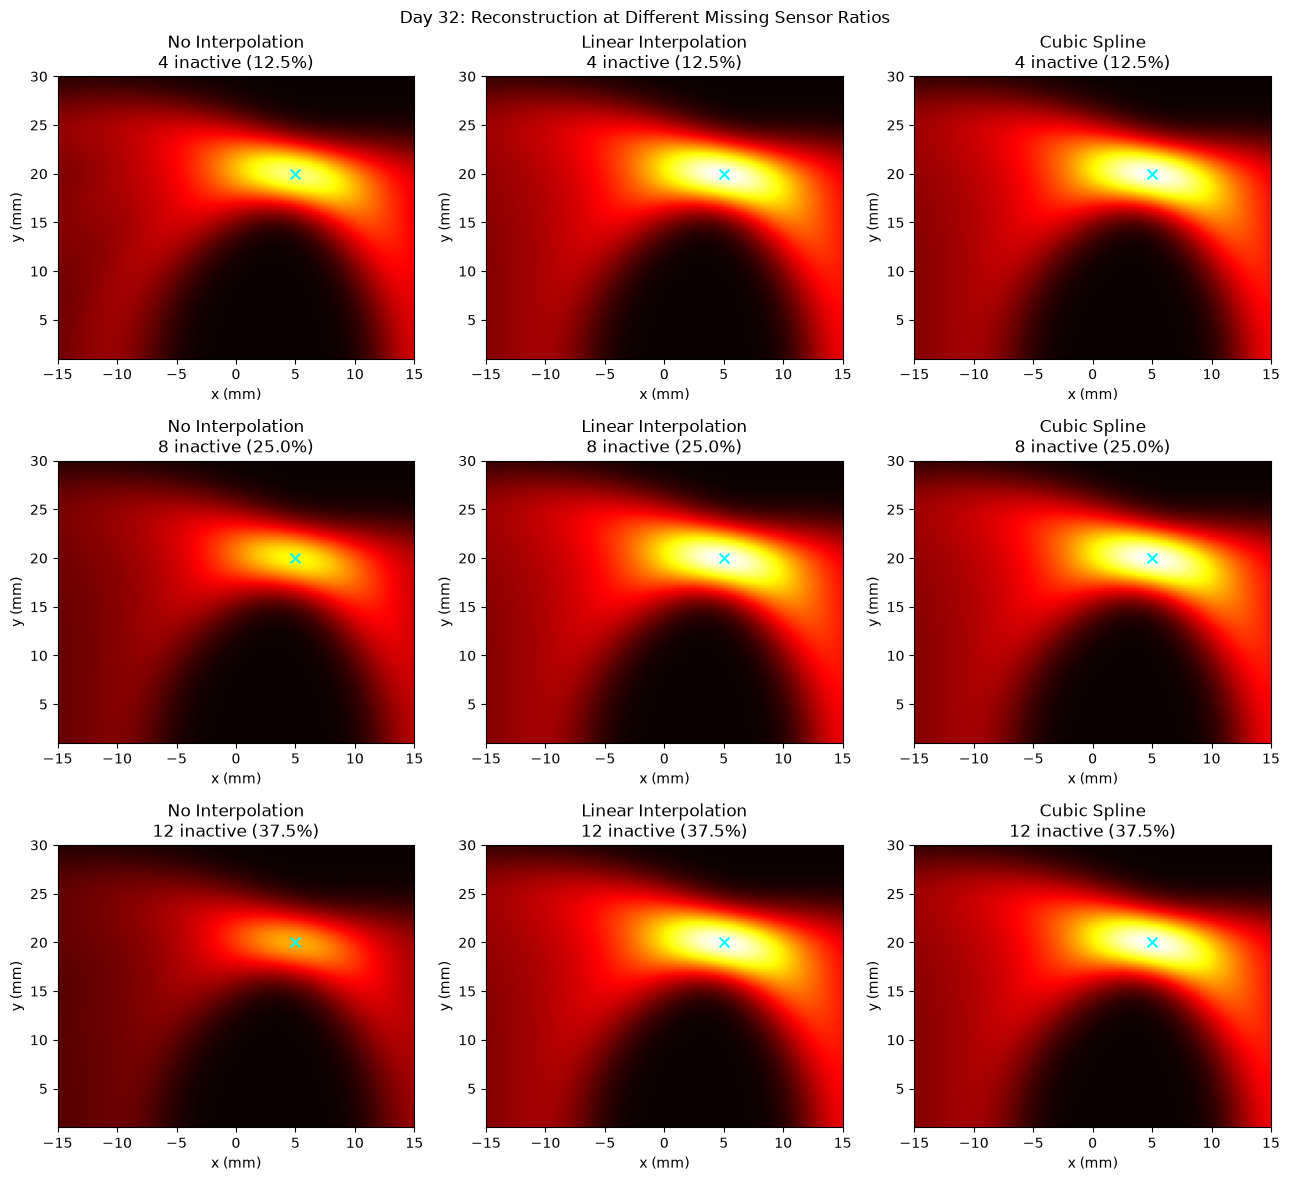

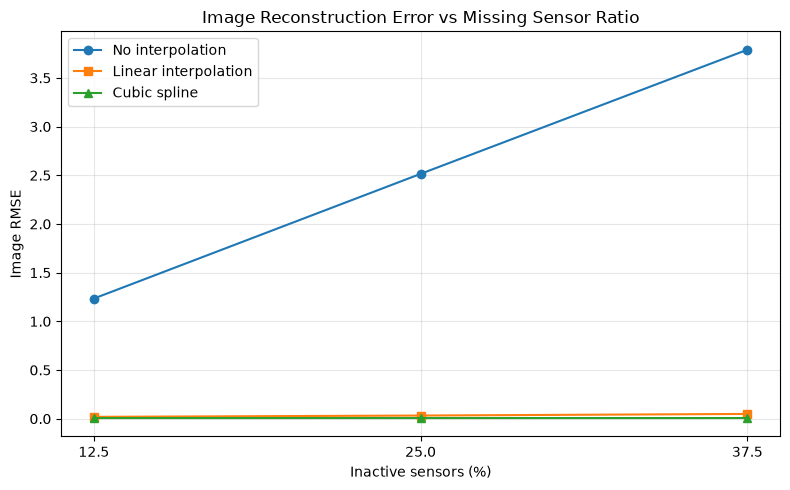


Results saved to: ..\outputs\day32_missing_sensor_ratio_results.json
Day 32 completed successfully!


In [1]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# --------------------------------------------------
# Day 32: Effect of Missing Sensor Ratio
# --------------------------------------------------

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation settings
num_sensors = 32
fs = 10e6
c = 1500.0
time = np.arange(600) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

# 2. Generate synthetic signals
signals_full = np.zeros((num_sensors, len(time)))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt((sx - source_x)**2 + source_y**2)
    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 3. Full-sensor DAS reference
x_grid = np.linspace(-15e-3, 15e-3, 100)
y_grid = np.linspace(1e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

def das_reconstruction(sensor_signals):
    image = np.zeros_like(X, dtype=float)

    for i, sx in enumerate(sensor_x):
        distances = np.sqrt((X - sx)**2 + Y**2)
        delays = distances / c

        sampled = np.interp(
            delays.ravel(),
            time,
            sensor_signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += sampled

    return image

image_full = das_reconstruction(signals_full)

# 4. Interpolation functions
def reconstruct_linear(signals_missing, active_mask):
    reconstructed = signals_missing.copy()
    active_x = sensor_x[active_mask]

    for j in range(len(time)):
        reconstructed[:, j] = np.interp(
            sensor_x,
            active_x,
            signals_missing[active_mask, j]
        )

    return reconstructed

def reconstruct_spline(signals_missing, active_mask):
    reconstructed = signals_missing.copy()

    spline = CubicSpline(
        sensor_x[active_mask],
        signals_missing[active_mask, :],
        axis=0,
        bc_type="natural",
        extrapolate=True
    )

    reconstructed[~active_mask, :] = spline(sensor_x[~active_mask])
    return reconstructed

def calculate_metrics(reference, estimate):
    error = estimate - reference
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "Max_Absolute_Error": float(np.max(np.abs(error)))
    }

# 5. Test different inactive sensor ratios
inactive_counts = [4, 8, 12]
results = {}
images_for_plot = {}

for n_inactive in inactive_counts:
    # Spread inactive sensors across the array
    inactive_indices = np.linspace(
        1, num_sensors - 2, n_inactive, dtype=int
    )

    active_mask = np.ones(num_sensors, dtype=bool)
    active_mask[inactive_indices] = False

    signals_missing = signals_full.copy()
    signals_missing[~active_mask, :] = 0.0

    signals_linear = reconstruct_linear(
        signals_missing, active_mask
    )
    signals_spline = reconstruct_spline(
        signals_missing, active_mask
    )

    image_missing = das_reconstruction(signals_missing)
    image_linear = das_reconstruction(signals_linear)
    image_spline = das_reconstruction(signals_spline)

    ratio_percent = 100 * n_inactive / num_sensors

    results[str(n_inactive)] = {
        "inactive_sensor_count": int(n_inactive),
        "inactive_ratio_percent": float(ratio_percent),
        "inactive_indices_zero_based": inactive_indices.tolist(),
        "image_metrics_vs_full_sensor_baseline": {
            "missing_without_interpolation": calculate_metrics(
                image_full, image_missing
            ),
            "linear_interpolation": calculate_metrics(
                image_full, image_linear
            ),
            "cubic_spline_interpolation": calculate_metrics(
                image_full, image_spline
            )
        }
    }

    images_for_plot[n_inactive] = {
        "missing": image_missing,
        "linear": image_linear,
        "spline": image_spline
    }

    print(f"\nInactive sensors: {n_inactive}/{num_sensors}")
    print(f"Inactive ratio: {ratio_percent:.1f}%")
    print("Linear metrics:",
          results[str(n_inactive)]
          ["image_metrics_vs_full_sensor_baseline"]
          ["linear_interpolation"])
    print("Spline metrics:",
          results[str(n_inactive)]
          ["image_metrics_vs_full_sensor_baseline"]
          ["cubic_spline_interpolation"])

# 6. Plot comparison for each inactive sensor ratio
fig, axes = plt.subplots(3, 3, figsize=(13, 12))

methods = [
    ("missing", "No Interpolation"),
    ("linear", "Linear Interpolation"),
    ("spline", "Cubic Spline")
]

vmax = max(float(np.max(image_full)), 1e-12)

for row, n_inactive in enumerate(inactive_counts):
    for col, (method_key, method_title) in enumerate(methods):
        ax = axes[row, col]
        image = (
            image_full if method_key == "reference"
            else images_for_plot[n_inactive][method_key]
        )

        ax.imshow(
            image,
            extent=[
                x_grid[0] * 1e3, x_grid[-1] * 1e3,
                y_grid[0] * 1e3, y_grid[-1] * 1e3
            ],
            origin="lower",
            aspect="auto",
            cmap="hot",
            vmin=0,
            vmax=vmax
        )

        ax.scatter(
            [source_x * 1e3], [source_y * 1e3],
            marker="x", color="cyan", s=50
        )

        ax.set_title(
            f"{method_title}\n{n_inactive} inactive "
            f"({100*n_inactive/num_sensors:.1f}%)"
        )
        ax.set_xlabel("x (mm)")
        ax.set_ylabel("y (mm)")

fig.suptitle("Day 32: Reconstruction at Different Missing Sensor Ratios")
plt.tight_layout()

plt.savefig(
    output_dir / "day32_reconstruction_by_missing_ratio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 7. Plot image RMSE versus missing sensor ratio
ratios = []
linear_rmse = []
spline_rmse = []
missing_rmse = []

for n_inactive in inactive_counts:
    entry = results[str(n_inactive)]
    ratios.append(entry["inactive_ratio_percent"])

    metrics = entry["image_metrics_vs_full_sensor_baseline"]
    missing_rmse.append(
        metrics["missing_without_interpolation"]["RMSE"]
    )
    linear_rmse.append(
        metrics["linear_interpolation"]["RMSE"]
    )
    spline_rmse.append(
        metrics["cubic_spline_interpolation"]["RMSE"]
    )

plt.figure(figsize=(8, 5))
plt.plot(ratios, missing_rmse, marker="o",
         label="No interpolation")
plt.plot(ratios, linear_rmse, marker="s",
         label="Linear interpolation")
plt.plot(ratios, spline_rmse, marker="^",
         label="Cubic spline")

plt.xlabel("Inactive sensors (%)")
plt.ylabel("Image RMSE")
plt.title("Image Reconstruction Error vs Missing Sensor Ratio")
plt.xticks(ratios)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day32_rmse_vs_missing_ratio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Save numerical results
final_results = {
    "day": 32,
    "project": "Photoacoustic inactive sensor reconstruction",
    "num_sensors": num_sensors,
    "reference": (
        "Full-sensor synthetic DAS image; not experimental ground truth."
    ),
    "results_by_inactive_sensor_count": results
}

with open(
    output_dir / "day32_missing_sensor_ratio_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(final_results, f, indent=4, ensure_ascii=False)

print("\nResults saved to:",
      output_dir / "day32_missing_sensor_ratio_results.json")
print("Day 32 completed successfully!")
